<a href="https://colab.research.google.com/github/blessed1adeoye/14thJuly2024_Sale_D_A/blob/ade/Hospital_ETL_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# === CELL 1: Install + configure (all sources from GitHub CSV) ===
# We install the libraries and define the six source URLs.
# Every source is a CSV from the same public GitHub repo.

# --- Install ---
!pip install -q pandas requests matplotlib

# --- Import ---
import pandas as pd
import requests
import re
import matplotlib.pyplot as plt

# --- Source URLs ---
# Six files, same BASE, same fetch method (pd.read_csv).
BASE = "https://raw.githubusercontent.com/blessed1adeoye/student/main"

# Structured (source 1)
URL_PATIENTS   = f"{BASE}/source1_patients.csv"
URL_ADMISSIONS = f"{BASE}/source1_admissions.csv"
URL_BILLING    = f"{BASE}/source1_billing.csv"

# Semi-structured, exported to CSV (source 2)
URL_LABS       = f"{BASE}/source2_labs.csv"
URL_DIAGNOSES  = f"{BASE}/source2_diagnoses.csv"

# Unstructured, exported to CSV with a note_text column (source 3)
URL_NOTES      = f"{BASE}/source3_clinical_notes.csv"

print("Config ready. All 6 sources from GitHub CSV.")

Config ready. All 6 sources from GitHub CSV.


In [ ]:
# https://drive.google.com/file/d/19C2qNj1vSwzRnEoQFZsjrgBvUJ7zWiL9/view?usp=sharing

In [ ]:
# https://drive.google.com/file/d/1C4ySEbgaJ3QMgX4ubRUfIVUhmdyo3z96/view?usp=sharing

In [3]:
# === CELL 2: Extract Source 1 (structured CSVs) ===
# Structured = fixed columns, typed values, tabular shape.
# Here we read three CSVs from GitHub into three DataFrames.

print("=== EXTRACT: Source 1 (structured) ===")

# pd.read_csv(url) downloads the file and parses it as a DataFrame.
df_patients   = pd.read_csv(URL_PATIENTS)      # 501 rows (incl. 1 duplicate on purpose)
df_admissions = pd.read_csv(URL_ADMISSIONS)    # 633 rows (some dirty on purpose)
df_billing    = pd.read_csv(URL_BILLING)       # 1783 rows of line-item bills

# .shape returns (rows, columns) — our first sanity check.
print(f"patients:   {df_patients.shape}")
print(f"admissions: {df_admissions.shape}")
print(f"billing:    {df_billing.shape}")

# Show the first 3 patient rows.
display(df_patients.head(3))

=== EXTRACT: Source 1 (structured) ===
patients:   (501, 10)
admissions: (633, 9)
billing:    (1783, 9)


,patient_id,first_name,last_name,gender,date_of_birth,phone,email,city,insurance_provider,bmi
0,PAT00001,Robert,Cole,Male,2009-12-18,+234-84026542351,jamesmichael@example.com,Lagos,AXA Mansard,22.6
1,PAT00002,Donna,Mejia,MALE,1942-01-12,+234-81316475255,elizabethmiles@example.net,Benin City,NHIS,37.0
2,PAT00003,Hailey,Robinson,Male,2022-11-25,+234-85030564139,jason76@example.net,Ibadan,AXA Mansard,38.0


In [ ]:
# https://drive.google.com/file/d/19C2qNj1vSwzRnEoQFZsjrgBvUJ7zWiL9/view?usp=sharing

In [4]:
# === CELL 3: Extract Source 2 (labs + diagnoses CSVs) ===
print("=== EXTRACT: Source 2 (labs + diagnoses) ===")

df_labs      = pd.read_csv(URL_LABS)
df_diagnoses = pd.read_csv(URL_DIAGNOSES)

print(f"labs:      {df_labs.shape}")
print(f"diagnoses: {df_diagnoses.shape}")

print("\n--- labs head ---")
display(df_labs.head(3))
print("\n--- diagnoses head ---")
display(df_diagnoses.head(3))

=== EXTRACT: Source 2 (labs + diagnoses) ===
labs:      (1917, 11)
diagnoses: (957, 7)

--- labs head ---


,lab_id,admission_id,patient_id,test_code,test_name,result_value,unit,reference_low,reference_high,is_abnormal,test_date
0,LAB00001,ADM00001,PAT00002,WBC,White Blood Cell,4.09,10^9/L,4.0,11.0,False,2023-04-16
1,LAB00002,ADM00002,PAT00003,WBC,White Blood Cell,8.38,10^9/L,4.0,11.0,False,2023-04-05
2,LAB00003,ADM00002,PAT00003,ALT,Alanine Transaminase,13.80,U/L,7.0,56.0,False,2023-04-02



--- diagnoses head ---


,diagnosis_id,admission_id,patient_id,icd10_code,diagnosis_name,severity,is_primary
0,DX00001,ADM00001,PAT00002,D50,Iron Deficiency Anaemia,Severe,True
1,DX00002,ADM00002,PAT00003,G43,Migraine,Episodic,True
2,DX00003,ADM00003,PAT00003,S72,Fracture of Femur,Closed,True


In [5]:
# === CELL 4: Extract Source 3 (clinical notes CSV) ===
# Unstructured = free-form prose. The note_text column holds raw text.
# We will mine structure out of it later with regex (Cell 8).

print("=== EXTRACT: Source 3 (unstructured notes) ===")

# Read the notes CSV. Each row = one admission's free-text note.
df_notes = pd.read_csv(URL_NOTES)

# Shape = (number of notes, 3 columns: admission_id, patient_id, note_text).
print(f"notes: {df_notes.shape}")

# Count empty notes (whitespace-only counts as empty).
# .fillna("") prevents NaNs from breaking .str accessor.
empty_count = (df_notes["note_text"].fillna("").str.strip() == "").sum()
print(f"empty notes: {empty_count}")

# Count truncated notes (ending with '...' — deliberately injected).
trunc_count = df_notes["note_text"].fillna("").str.strip().str.endswith("...").sum()
print(f"truncated (end with '...'): {trunc_count}")

# Print one full note to see what raw unstructured data looks like.
print("\n--- first note ---")
print(df_notes.iloc[0]["note_text"])

=== EXTRACT: Source 3 (unstructured notes) ===
notes: (633, 3)
empty notes: 10
truncated (end with '...'): 67

--- first note ---
CLINICAL SUMMARY — ICU
Mr/Ms Donna Mejia (84y, Male) presented on 2023-04-14. History of never smoking, BMI 37.0. Working dx: Iron Deficiency Anaemia (D50, Severe). Investigations: White Blood Cell 4.09 10^9/L. Course: lower back pain after fall. Discharged 2023-04-17; outpatient review in 1 weeks. Condition: stable.


In [6]:
# === CELL 5: Staging — profile the data BEFORE cleaning ===
# Data engineers always measure problems before fixing them.

print("=== STAGING AREA: profile BEFORE transform ===\n")

# --- Patients nulls ---
# .isna().sum() = count of nulls per column.
print("--- patients nulls ---")
print(df_patients.isna().sum())

# --- Admissions problems ---
# Future date > 2100 is an injected sentinel value.
# errors="coerce" turns unparseable strings into NaT (so comparison won't crash).
future_dates = (
    pd.to_datetime(df_admissions["admission_date"], errors="coerce") > "2100-01-01"
).sum()
print("\n--- admissions problems ---")
print(f"future admission_date (>2100): {future_dates}")

# Negative length_of_stay is impossible.
print(f"negative length_of_stay: {(df_admissions['length_of_stay_days'] < 0).sum()}")

# Null department = missing categorical.
print(f"null department: {df_admissions['department'].isna().sum()}")

# --- Labs problems ---
# Orphan = lab whose patient_id is not in the patient master.
orphans = (~df_labs["patient_id"].isin(df_patients["patient_id"])).sum()
print("\n--- labs problems ---")
print(f"orphan patient_id (not in patients): {orphans}")

# Detect mixed date formats: extract the pattern, then normalize digits.
patterns = df_labs["test_date"].astype(str).str.extract(
    r"(\d{4}-\d{2}-\d{2}|\d{2}/\d{2}/\d{4}|\d{2}-\d{2}-\d{4})"
)[0].str.replace(r"\d", "9", regex=True)
print(f"test_date formats seen: {patterns.value_counts().to_dict()}")

=== STAGING AREA: profile BEFORE transform ===

--- patients nulls ---
patient_id             0
first_name             0
last_name              0
gender                 0
date_of_birth          0
phone                 25
email                  0
city                   0
insurance_provider     0
bmi                    0
dtype: int64

--- admissions problems ---
future admission_date (>2100): 0
negative length_of_stay: 1
null department: 1

--- labs problems ---
orphan patient_id (not in patients): 1
test_date formats seen: {'9999-99-99': 1915, '99/99/9999': 1, '99-99-9999': 1}


In [7]:
# === CELL 6: Transform Source 1 ===
# Each fix matches a real hospital data-quality policy.

print("=== TRANSFORM: Source 1 ===\n")

# --- Patients ---
# 1. Deduplicate: the generator added a duplicate registration row.
before = len(df_patients)
df_patients = df_patients.drop_duplicates(subset="patient_id", keep="first").copy()
print(f"patients: {before} -> {len(df_patients)} after dedupe")

# 2. Normalize gender casing: MALE -> Male, female -> Female.
df_patients["gender"] = df_patients["gender"].str.title()

# 3. Null out invalid emails (typo like "not-an-email").
bad_email = ~df_patients["email"].fillna("").str.contains("@")
df_patients.loc[bad_email, "email"] = None
print(f"bad emails nulled: {bad_email.sum()}")

# 4. Fill missing phones with "UNKNOWN" (patients who declined).
df_patients["phone"] = df_patients["phone"].fillna("UNKNOWN")

# 5. Derive full_name and age.
df_patients["full_name"] = df_patients["first_name"] + " " + df_patients["last_name"]
df_patients["date_of_birth"] = pd.to_datetime(df_patients["date_of_birth"], errors="coerce")
df_patients["age"] = (
    (pd.Timestamp.today() - df_patients["date_of_birth"]).dt.days // 365
).astype("Int64")   # Int64 (capital I) preserves NaN when casting

# --- Admissions ---
# Parse both date columns into datetime.
df_admissions["admission_date"] = pd.to_datetime(df_admissions["admission_date"], errors="coerce")
df_admissions["discharge_date"] = pd.to_datetime(df_admissions["discharge_date"], errors="coerce")

# Future admission dates -> NaT.
future = df_admissions["admission_date"] > "2100-01-01"
df_admissions.loc[future, "admission_date"] = pd.NaT
print(f"future admission dates nulled: {future.sum()}")

# Discharge before admission -> NaT discharge.
bad_order = df_admissions["discharge_date"] < df_admissions["admission_date"]
df_admissions.loc[bad_order, "discharge_date"] = pd.NaT
print(f"discharge<admission nulled: {bad_order.sum()}")

# Negative LOS -> recompute from dates.
neg_los = df_admissions["length_of_stay_days"] < 0
df_admissions.loc[neg_los, "length_of_stay_days"] = (
    df_admissions.loc[neg_los, "discharge_date"]
    - df_admissions.loc[neg_los, "admission_date"]
).dt.days
print(f"negative LOS recomputed: {neg_los.sum()}")

# Null department -> "Unknown".
df_admissions["department"] = df_admissions["department"].fillna("Unknown")

# --- Billing ---
# Negative bills -> 0.
neg_bill = df_billing["total_amount"] < 0
df_billing.loc[neg_bill, "total_amount"] = 0
print(f"negative bills set to 0: {neg_bill.sum()}")

# Null payment status -> "Unknown".
df_billing["payment_status"] = df_billing["payment_status"].fillna("Unknown")

# Parse billing_date.
df_billing["billing_date"] = pd.to_datetime(df_billing["billing_date"], errors="coerce")

print("\nDone. patients / admissions / billing cleaned.")

=== TRANSFORM: Source 1 ===

patients: 501 -> 500 after dedupe
bad emails nulled: 1
future admission dates nulled: 0
discharge<admission nulled: 2
negative LOS recomputed: 1
negative bills set to 0: 1

Done. patients / admissions / billing cleaned.


In [8]:
# === CELL 7: Transform Source 2 ===
# Two classic semi-structured problems: mixed date formats and inconsistent units.

print("=== TRANSFORM: Source 2 ===\n")

# --- 1. Parse mixed date formats ---
# Try ISO, US, and EU formats. Return NaT if none match.
def parse_mixed_date(x):
    if pd.isna(x):
        return pd.NaT
    for fmt in ("%Y-%m-%d", "%m/%d/%Y", "%d-%m-%Y"):
        try:
            return pd.to_datetime(x, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

df_labs["test_date"] = df_labs["test_date"].apply(parse_mixed_date)
print(f"unparseable test_dates: {df_labs['test_date'].isna().sum()}")

# --- 2. Fix inconsistent unit for HGB ---
# HGB must be g/dL. Any HGB row with unit "mmol/L" was injected wrong.
wrong_hgb_unit = (df_labs["test_code"] == "HGB") & (df_labs["unit"] == "mmol/L")
df_labs.loc[wrong_hgb_unit, "unit"] = "g/dL"
print(f"HGB rows fixed: {wrong_hgb_unit.sum()}")

# --- 3. Recompute is_abnormal from value vs range ---
df_labs["is_abnormal"] = (
    (df_labs["result_value"] < df_labs["reference_low"]) |
    (df_labs["result_value"] > df_labs["reference_high"])
)

# --- 4. Drop orphan labs ---
before = len(df_labs)
df_labs = df_labs[df_labs["patient_id"].isin(df_patients["patient_id"])].copy()
print(f"orphan labs dropped: {before - len(df_labs)}")

# --- 5. Fill missing severity ---
df_diagnoses["severity"] = df_diagnoses["severity"].fillna("Unspecified")

print("\nDone. labs / diagnoses cleaned.")

=== TRANSFORM: Source 2 ===

unparseable test_dates: 0
HGB rows fixed: 1
orphan labs dropped: 1

Done. labs / diagnoses cleaned.


In [10]:
# === CELL 8: Transform Source 3 — regex extraction ===
# Convert free text into structured columns using regular expressions.
# pandas reads empty CSV cells as NaN (float), which breaks regex.
# We cast note_text to string BEFORE the apply.

print("=== TRANSFORM: Source 3 (regex extraction) ===\n")

# Ensure every note is a string (NaN becomes "").
df_notes["note_text"] = df_notes["note_text"].fillna("").astype(str)

def extract_from_note(text):
    """Parse one clinical note into structured fields."""
    # Guard: ensure text is a string.
    text = str(text) if text is not None else ""

    # Start with nulls for every field.
    out = {
        "department": None, "adm_date": None, "disch_date": None,
        "diagnosis": None, "condition": None, "followup_weeks": None,
        "note_empty": bool(not text.strip()),
        "note_truncated": bool(text.strip().endswith("...")),
    }
    # If the note is empty or truncated, we can't reliably extract fields.
    if out["note_empty"] or out["note_truncated"]:
        return out

    # Department: "CLINICAL SUMMARY — ICU" OR "Department: Oncology"
    m = re.search(r"CLINICAL SUMMARY\s*[—\-]\s*(\w[\w\s]*?)\n", text)
    if not m:
        m = re.search(r"Department:\s*([\w\s]+?)\n", text)
    if m:
        out["department"] = m.group(1).strip()

    # Admission date: "presented on YYYY-MM-DD" OR "Admitted: YYYY-MM-DD"
    m = re.search(r"presented on (\d{4}-\d{2}-\d{2})", text) or \
        re.search(r"Admitted:\s*(\d{4}-\d{2}-\d{2})", text)
    if m:
        out["adm_date"] = m.group(1)

    # Discharge date: "Discharged [on] YYYY-MM-DD" OR "Discharged: YYYY-MM-DD"
    m = re.search(r"Discharged (?:on )?(\d{4}-\d{2}-\d{2})", text) or \
        re.search(r"Discharged:\s*(\d{4}-\d{2}-\d{2})", text)
    if m:
        out["disch_date"] = m.group(1)

    # Diagnosis: text before "(" or "[" which holds the ICD code.
    m = re.search(
        r"(?:Working dx|Primary diagnosis|Diagnosis):\s*([A-Za-z][^(\\[]+?)\s*[\(\[]",
        text
    )
    if m:
        out["diagnosis"] = m.group(1).strip()

    # Condition: "Condition: stable" OR "in stable condition" OR "discharged stable,"
    m = re.search(r"Condition:\s*(\w+)", text) or \
        re.search(r"in (\w+) condition", text) or \
        re.search(r"discharged (\w+),", text)
    if m:
        out["condition"] = m.group(1)

    # Follow-up weeks: "follow-up in N weeks" OR "review in N weeks"
    m = re.search(r"follow-up in (\d+) weeks", text, re.IGNORECASE) or \
        re.search(r"review in (\d+) weeks", text, re.IGNORECASE)
    if m:
        out["followup_weeks"] = int(m.group(1))

    return out

# Apply the parser to every note.
parsed = df_notes["note_text"].apply(extract_from_note).apply(pd.Series)

# Combine identifiers + parsed fields.
df_notes_enriched = pd.concat([df_notes[["admission_id", "patient_id"]], parsed], axis=1)

# Coverage report.
print(f"notes total: {len(df_notes_enriched)}")
print(f"  empty:      {df_notes_enriched['note_empty'].sum()}")
print(f"  truncated:  {df_notes_enriched['note_truncated'].sum()}")
print(f"  extracted department: {(~df_notes_enriched['department'].isna()).sum()}")
print(f"  extracted diagnosis:  {(~df_notes_enriched['diagnosis'].isna()).sum()}")
print(f"  extracted condition:  {(~df_notes_enriched['condition'].isna()).sum()}")
print(f"  extracted follow-up:  {(~df_notes_enriched['followup_weeks'].isna()).sum()}")

print("\n--- sample extracted ---")
display(df_notes_enriched.dropna(subset=["department"]).head(5))

=== TRANSFORM: Source 3 (regex extraction) ===

notes total: 633
  empty:      10
  truncated:  67
  extracted department: 350
  extracted diagnosis:  556
  extracted condition:  556
  extracted follow-up:  556

--- sample extracted ---


,admission_id,patient_id,department,adm_date,disch_date,diagnosis,condition,followup_weeks,note_empty,note_truncated
0,ADM00001,PAT00002,ICU,2023-04-14,2023-04-17,Iron Deficiency Anaemia,stable,1.0,False,False
1,ADM00002,PAT00003,Oncology,2023-04-02,2023-04-05,Migraine,stable,4.0,False,False
4,ADM00005,PAT00005,Orthopedics,2023-08-12,2023-08-17,Malignant Neoplasm of Lung,improved,4.0,False,False
6,ADM00007,PAT00007,Cardiology,2023-09-06,2023-09-08,Pneumonia,recovered,4.0,False,False
7,ADM00008,PAT00010,Neurology,2024-01-12,2024-01-14,Acute Myocardial Infarction,improved,1.0,False,False


In [11]:
# === CELL 9: Build star schema (4 dimensions + 1 fact) ===

print("=== BUILD STAR SCHEMA ===\n")

# dim_patient — one row per patient, descriptive attributes.
dim_patient = df_patients[[
    "patient_id", "first_name", "last_name", "full_name", "gender",
    "date_of_birth", "age", "city", "insurance_provider", "bmi"
]].copy()
dim_patient["date_of_birth"] = dim_patient["date_of_birth"].dt.date

# dim_department — unique department names + surrogate key.
dept_list = sorted(df_admissions["department"].dropna().unique())
dim_department = pd.DataFrame({"department": dept_list})
dim_department.insert(0, "department_id", range(1, len(dim_department) + 1))
print(f"dim_department: {len(dim_department)} rows")

# dim_diagnosis — one row per diagnosis_id.
dim_diagnosis = df_diagnoses[[
    "diagnosis_id", "icd10_code", "diagnosis_name", "severity"
]].drop_duplicates(subset="diagnosis_id").copy()

# dim_date — one row per distinct date seen in admissions.
all_dates = pd.concat([
    df_admissions["admission_date"], df_admissions["discharge_date"]
]).dropna().dt.date.unique()
dim_date = pd.DataFrame({"date_id": sorted(all_dates)})
dim_date["date_id"]  = pd.to_datetime(dim_date["date_id"])
dim_date["year"]     = dim_date["date_id"].dt.year
dim_date["month"]    = dim_date["date_id"].dt.month
dim_date["day"]      = dim_date["date_id"].dt.day
dim_date["weekday"]  = dim_date["date_id"].dt.day_name()
dim_date["date_id"]  = dim_date["date_id"].dt.date
print(f"dim_date: {len(dim_date)} rows")

# fact_admission — one row per admission.
# Aggregate billing to per-admission totals.
billing_agg = df_billing.groupby("admission_id").agg(
    total_bill_amount=("total_amount", "sum"),
    billing_date=("billing_date", "max"),
    payment_status=("payment_status", "first"),
).reset_index()

# Primary diagnosis per admission.
primary_dx = df_diagnoses[df_diagnoses["is_primary"]][
    ["admission_id", "diagnosis_id"]
].drop_duplicates(subset="admission_id")

# Join everything together.
fact = (
    df_admissions
    .merge(dim_department[["department_id", "department"]], on="department", how="left")
    .merge(primary_dx, on="admission_id", how="left")
    .merge(billing_agg, on="admission_id", how="left")
    .merge(df_notes_enriched[["admission_id", "condition", "followup_weeks", "note_empty"]],
           on="admission_id", how="left")
)

# Select and rename to warehouse names.
fact_admission = fact[[
    "admission_id", "patient_id", "department_id", "diagnosis_id",
    "admission_date", "discharge_date", "length_of_stay_days",
    "total_bill_amount", "billing_date", "payment_status",
    "condition", "followup_weeks", "note_empty",
]].rename(columns={"condition": "discharge_condition", "note_empty": "note_found"})

# Invert note_found: True means the note existed.
fact_admission["note_found"] = ~fact_admission["note_found"].fillna(True)

# Cast dates to Python date.
for c in ["admission_date", "discharge_date", "billing_date"]:
    fact_admission[c] = pd.to_datetime(fact_admission[c], errors="coerce").dt.date

print(f"fact_admission: {len(fact_admission)} rows")
print("\n--- fact_admission head ---")
display(fact_admission.head(3))

=== BUILD STAR SCHEMA ===

dim_department: 9 rows
dim_date: 679 rows
fact_admission: 633 rows

--- fact_admission head ---


,admission_id,patient_id,department_id,diagnosis_id,admission_date,discharge_date,length_of_stay_days,total_bill_amount,billing_date,payment_status,discharge_condition,followup_weeks,note_found
0,ADM00001,PAT00002,4,DX00001,2023-04-14,2023-04-17,3,208014.07,2023-04-17,Partial,stable,1.0,True
1,ADM00002,PAT00003,6,DX00002,2023-04-02,2023-04-05,3,17954.55,2023-04-05,Partial,stable,4.0,True
2,ADM00003,PAT00003,2,DX00003,2024-09-29,2024-10-06,7,228774.66,2024-10-06,Insurance,stable,2.0,True


In [12]:
# === CELL 10: Assemble warehouse in memory ===
# GitHub-only version: no Postgres. Everything stays as DataFrames.
# We keep the star schema intact so students see the same shape.

warehouse = {
    "dim_patient":    dim_patient,
    "dim_department": dim_department,
    "dim_diagnosis":  dim_diagnosis,
    "dim_date":       dim_date,
    "fact_admission": fact_admission,
}

print("=== LOAD: warehouse assembled ===\n")
for name, df in warehouse.items():
    print(f"  {name:18} -> {len(df):>6} rows")
print("\nDone. Warehouse in memory.")

=== LOAD: warehouse assembled ===

  dim_patient        ->    500 rows
  dim_department     ->      9 rows
  dim_diagnosis      ->    957 rows
  dim_date           ->    679 rows
  fact_admission     ->    633 rows

Done. Warehouse in memory.


=== ANALYZE: Hospital KPIs ===

KPI 1: Avg length of stay by department


,department,avg_los_days,admissions
0,Unknown,9.00,1
1,Emergency,5.49,76
2,Pediatrics,5.22,77
3,General Medicine,4.90,68
4,Neurology,4.76,79
5,Orthopedics,4.60,91
6,ICU,4.49,86
7,Oncology,4.47,74
8,Cardiology,4.25,81


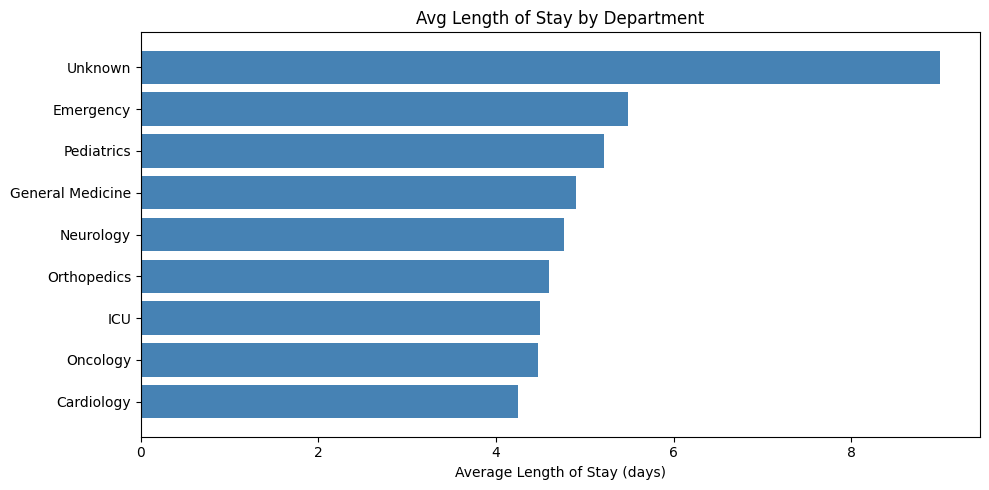

In [13]:
# === CELL 11: Analyze — 3 hospital KPIs ===

print("=== ANALYZE: Hospital KPIs ===\n")

# --- KPI 1: Avg length of stay by department ---
kpi1 = (
    fact_admission[fact_admission["length_of_stay_days"] > 0]
    .merge(dim_department, on="department_id", how="left")
    .groupby("department")
    .agg(avg_los_days=("length_of_stay_days", "mean"),
         admissions=("admission_id", "count"))
    .round(2)
    .sort_values("avg_los_days", ascending=False)
    .reset_index()
)
print("KPI 1: Avg length of stay by department")
display(kpi1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(kpi1["department"], kpi1["avg_los_days"], color="steelblue")
ax.set_xlabel("Average Length of Stay (days)")
ax.set_title("Avg Length of Stay by Department")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

KPI 2: Abnormal lab rate by diagnosis (top 10)


,diagnosis_name,total_labs,abnormal_labs,abnormal_pct
6,Iron Deficiency Anaemia,185,42,22.7
9,Migraine,163,34,20.9
7,Malignant Neoplasm of Breast,174,36,20.7
2,Chronic Kidney Disease,152,31,20.4
4,Fracture of Femur,167,33,19.8
11,Type 2 Diabetes Mellitus,145,28,19.3
10,Pneumonia,178,30,16.9
0,Acute Myocardial Infarction,213,34,16.0
3,Essential Hypertension,132,19,14.4
5,Infectious Gastroenteritis,177,24,13.6


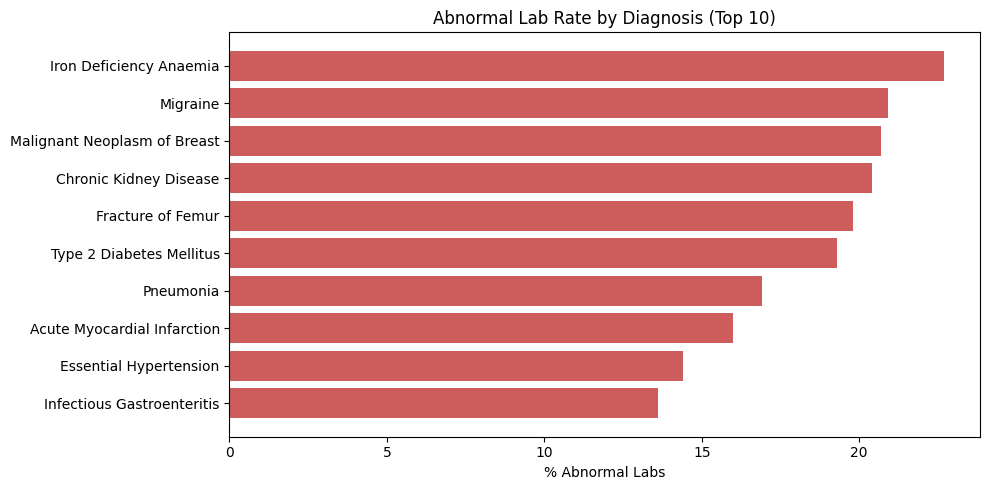

In [14]:
# === CELL 11b: KPI 2 — Abnormal lab rate by diagnosis ===

# Map admission -> diagnosis name.
fact_dx = fact_admission[["admission_id", "diagnosis_id"]].merge(
    dim_diagnosis[["diagnosis_id", "diagnosis_name"]], on="diagnosis_id", how="left"
)

# Join labs to the map, then aggregate.
kpi2 = (
    df_labs.merge(fact_dx, on="admission_id", how="inner")
    .groupby("diagnosis_name")
    .agg(total_labs=("lab_id", "count"),
         abnormal_labs=("is_abnormal", "sum"))
    .reset_index()
)
kpi2["abnormal_pct"] = (100 * kpi2["abnormal_labs"] / kpi2["total_labs"]).round(1)
kpi2 = kpi2.sort_values("abnormal_pct", ascending=False).head(10)

print("KPI 2: Abnormal lab rate by diagnosis (top 10)")
display(kpi2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(kpi2["diagnosis_name"], kpi2["abnormal_pct"], color="indianred")
ax.set_xlabel("% Abnormal Labs")
ax.set_title("Abnormal Lab Rate by Diagnosis (Top 10)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

KPI 3: Revenue by insurance provider


,insurance_provider,total_revenue,admissions
0,Hygeia HMO,21097330.36,122
1,Self-Pay,17787648.91,106
2,Leadway Health,16411855.71,113
3,NHIS,14687743.86,94
4,AXA Mansard,13516484.50,105
5,Reliance HMO,13374233.13,93


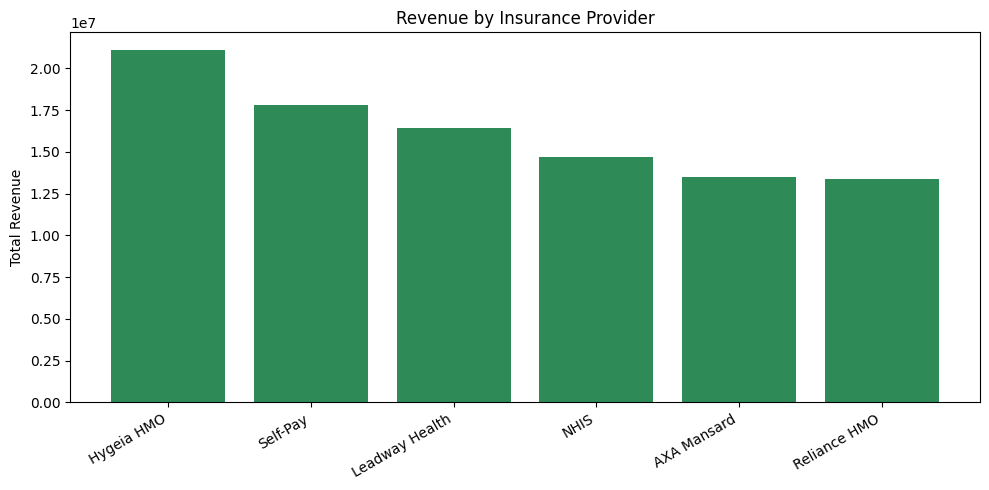

In [15]:
# === CELL 11c: KPI 3 — Revenue by insurance provider ===

kpi3 = (
    fact_admission
    .merge(dim_patient[["patient_id", "insurance_provider"]],
           on="patient_id", how="left")
    .dropna(subset=["total_bill_amount"])
    .groupby("insurance_provider")
    .agg(total_revenue=("total_bill_amount", "sum"),
         admissions=("admission_id", "count"))
    .round(2)
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)
print("KPI 3: Revenue by insurance provider")
display(kpi3)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(kpi3["insurance_provider"], kpi3["total_revenue"], color="seagreen")
ax.set_ylabel("Total Revenue")
ax.set_title("Revenue by Insurance Provider")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [16]:
# === CELL 12: Verify warehouse row counts ===

print("=== VERIFY: warehouse row counts ===\n")
for name, df in warehouse.items():
    print(f"  warehouse[{name!r}] = {len(df)} rows")

=== VERIFY: warehouse row counts ===

  warehouse['dim_patient'] = 500 rows
  warehouse['dim_department'] = 9 rows
  warehouse['dim_diagnosis'] = 957 rows
  warehouse['dim_date'] = 679 rows
  warehouse['fact_admission'] = 633 rows


In [20]:
# === CELL 13: Interactive Dashboard with Dash (inline in Colab) ===
# Install Dash and comm (required for Colab integration)
!pip install -q dash comm

import plotly.express as px
from dash import Dash, dcc, html
from dash.dependencies import Input, Output
import pandas as pd

# --- Prepare the data from your in-memory warehouse ---
fact = warehouse["fact_admission"]
dim_dept = warehouse["dim_department"]

# Filter out invalid length of stay (<= 0) for a meaningful average.
df_dash = fact[fact["length_of_stay_days"] > 0].merge(
    dim_dept, on="department_id", how="left"
)

# Get a sorted list of unique departments for the dropdown menu.
dept_options = sorted(df_dash["department"].dropna().unique())

# --- Build the Dash App ---
app = Dash(__name__)

app.layout = html.Div([
    html.H2("Hospital Operations Dashboard"),
    html.Label("Select a Department:"),
    dcc.Dropdown(
        id="dept-dropdown",
        options=[{"label": d, "value": d} for d in dept_options],
        value=dept_options[0] if dept_options else None,
        clearable=False,
        style={"width": "50%"}
    ),
    dcc.Graph(id="los-bar-chart")
])

# --- Define the Callback ---
@app.callback(
    Output("los-bar-chart", "figure"),
    Input("dept-dropdown", "value")
)
def update_chart(selected_dept):
    filtered = df_dash[df_dash["department"] == selected_dept]

    fig = px.histogram(
        filtered,
        x="length_of_stay_days",
        title=f"Length of Stay Distribution in {selected_dept}",
        labels={"length_of_stay_days": "Length of Stay (Days)"}
    )
    return fig

# --- Run the App Inline ---
# Use app.run() with jupyter_mode="inline" for Colab
app.run(jupyter_mode="inline", debug=False)

<IPython.core.display.Javascript object>

In [19]:
import plotly.express as px
fact = warehouse["fact_admission"]
dim = warehouse["dim_department"]
df_plot = fact[fact["length_of_stay_days"] > 0].merge(dim, on="department_id")
avg_los = df_plot.groupby("department")["length_of_stay_days"].mean().reset_index()
fig = px.bar(avg_los, x="department", y="length_of_stay_days", title="Avg LOS by Department")
fig.show()

In [22]:
# === CELL 13: Multi-chart interactive dashboard (Dash) ===
# 3 filters (department, insurance, date) drive 3 charts + 3 KPI cards.
# Runs inline in Colab via jupyter_mode="inline".

# --- Install dependencies ---
# dash: the framework
# comm: needed for Colab inline rendering
!pip install -q dash comm

import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, dcc, html
from dash.dependencies import Input, Output
import pandas as pd

# ============================================================
# 1) Prepare one flat DataFrame for the dashboard
# ============================================================
# Merge the fact table with the dimensions once, so the callbacks
# can filter a single DataFrame instead of re-joining every time.

fact = warehouse["fact_admission"].copy()
dim_p  = warehouse["dim_patient"]
dim_d  = warehouse["dim_department"]
dim_dx = warehouse["dim_diagnosis"]

# Merge descriptive columns onto the fact table.
df = (
    fact
    .merge(dim_p[["patient_id", "insurance_provider", "gender", "age"]],
           on="patient_id", how="left")
    .merge(dim_d[["department_id", "department"]],
           on="department_id", how="left")
    .merge(dim_dx[["diagnosis_id", "diagnosis_name", "severity"]],
           on="diagnosis_id", how="left")
)

# Parse dates once so filtering works.
df["admission_date"] = pd.to_datetime(df["admission_date"], errors="coerce")
df["discharge_date"] = pd.to_datetime(df["discharge_date"], errors="coerce")

# Drop rows without a valid admission date (can't filter on missing dates).
df = df.dropna(subset=["admission_date"])

# ============================================================
# 2) Build the filter option lists
# ============================================================
dept_options = sorted(df["department"].dropna().unique().tolist())
ins_options  = sorted(df["insurance_provider"].dropna().unique().tolist())

min_date = df["admission_date"].min().date()
max_date = df["admission_date"].max().date()

# ============================================================
# 3) Layout: header, 3 filters, 3 KPI cards, 3 charts
# ============================================================
app = Dash(__name__)

app.layout = html.Div([
    html.H2("🏥 Hospital Operations Dashboard",
            style={"textAlign": "center", "marginBottom": 20}),

    # --- Filter row ---
    html.Div([
        html.Div([
            html.Label("Department"),
            dcc.Dropdown(
                id="f-dept",
                options=[{"label": d, "value": d} for d in dept_options],
                value=dept_options,          # default: all
                multi=True,
                placeholder="All departments"
            ),
        ], style={"width": "32%", "display": "inline-block",
                  "paddingRight": "2%"}),

        html.Div([
            html.Label("Insurance Provider"),
            dcc.Dropdown(
                id="f-ins",
                options=[{"label": i, "value": i} for i in ins_options],
                value=ins_options,           # default: all
                multi=True,
                placeholder="All insurers"
            ),
        ], style={"width": "32%", "display": "inline-block",
                  "paddingRight": "2%"}),

        html.Div([
            html.Label("Admission Date Range"),
            dcc.DatePickerRange(
                id="f-date",
                min_date_allowed=min_date,
                max_date_allowed=max_date,
                start_date=min_date,
                end_date=max_date
            ),
        ], style={"width": "32%", "display": "inline-block"}),
    ], style={"marginBottom": 20}),

    # --- KPI cards ---
    html.Div(id="kpi-cards", style={
        "display": "flex", "gap": "20px", "marginBottom": 20
    }),

    # --- Charts row ---
    html.Div([
        html.Div(dcc.Graph(id="chart-los"),  style={"width": "50%",
                                                    "display": "inline-block"}),
        html.Div(dcc.Graph(id="chart-dx"),   style={"width": "50%",
                                                    "display": "inline-block"}),
    ]),
    html.Div([
        dcc.Graph(id="chart-rev"),
    ]),
])

# ============================================================
# 4) One callback updates KPIs + all 3 charts
# ============================================================
@app.callback(
    [Output("kpi-cards", "children"),
     Output("chart-los", "figure"),
     Output("chart-dx", "figure"),
     Output("chart-rev", "figure")],
    [Input("f-dept", "value"),
     Input("f-ins", "value"),
     Input("f-date", "start_date"),
     Input("f-date", "end_date")]
)
def update_dashboard(sel_depts, sel_ins, start_date, end_date):
    # --- Apply filters ---
    mask = pd.Series(True, index=df.index)
    if sel_depts:
        mask &= df["department"].isin(sel_depts)
    if sel_ins:
        mask &= df["insurance_provider"].isin(sel_ins)
    if start_date and end_date:
        mask &= (df["admission_date"] >= pd.Timestamp(start_date)) & \
                (df["admission_date"] <= pd.Timestamp(end_date))
    fdf = df[mask]

    # --- KPI 1: total admissions ---
    n_adm = len(fdf)

    # --- KPI 2: average LOS (only valid, positive LOS) ---
    los_valid = fdf[fdf["length_of_stay_days"] > 0]["length_of_stay_days"]
    avg_los = round(los_valid.mean(), 1) if len(los_valid) > 0 else 0

    # --- KPI 3: total revenue ---
    total_rev = round(fdf["total_bill_amount"].sum(), 0)

    kpi_cards = [
        html.Div([
            html.H4("Admissions", style={"margin": 0}),
            html.H2(f"{n_adm:,}", style={"margin": 0, "color": "#2c3e50"}),
        ], style={"background": "#ecf0f1", "padding": "15px",
                  "borderRadius": "8px", "flex": "1", "textAlign": "center"}),

        html.Div([
            html.H4("Avg Length of Stay (days)", style={"margin": 0}),
            html.H2(f"{avg_los}", style={"margin": 0, "color": "#2980b9"}),
        ], style={"background": "#ecf0f1", "padding": "15px",
                  "borderRadius": "8px", "flex": "1", "textAlign": "center"}),

        html.Div([
            html.H4("Total Revenue", style={"margin": 0}),
            html.H2(f"₦{total_rev:,.0f}", style={"margin": 0, "color": "#27ae60"}),
        ], style={"background": "#ecf0f1", "padding": "15px",
                  "borderRadius": "8px", "flex": "1", "textAlign": "center"}),
    ]

    # --- Chart 1: Avg LOS by department ---
    if len(fdf) > 0:
        los_by_dept = (
            fdf[fdf["length_of_stay_days"] > 0]
            .groupby("department")["length_of_stay_days"]
            .mean().reset_index()
            .sort_values("length_of_stay_days", ascending=False)
        )
        fig_los = px.bar(
            los_by_dept, x="department", y="length_of_stay_days",
            title="Average Length of Stay by Department",
            labels={"length_of_stay_days": "Avg LOS (days)", "department": ""},
            color="length_of_stay_days", color_continuous_scale="Blues"
        )
        fig_los.update_layout(coloraxis_showscale=False)
    else:
        fig_los = go.Figure().update_layout(title="No data for selected filters")

    # --- Chart 2: Admission count by diagnosis (top 10) ---
    if len(fdf) > 0:
        by_dx = (
            fdf.dropna(subset=["diagnosis_name"])
            .groupby("diagnosis_name")
            .size().reset_index(name="admissions")
            .sort_values("admissions", ascending=False)
            .head(10)
        )
        fig_dx = px.bar(
            by_dx, x="admissions", y="diagnosis_name", orientation="h",
            title="Top 10 Diagnoses by Admission Count",
            labels={"admissions": "Admissions", "diagnosis_name": ""},
            color="admissions", color_continuous_scale="Reds"
        )
        fig_dx.update_layout(yaxis={"categoryorder": "total ascending"},
                             coloraxis_showscale=False)
    else:
        fig_dx = go.Figure().update_layout(title="No data for selected filters")

    # --- Chart 3: Revenue by insurance provider ---
    if len(fdf) > 0:
        by_ins = (
            fdf.groupby("insurance_provider")["total_bill_amount"]
            .sum().reset_index()
            .sort_values("total_bill_amount", ascending=False)
        )
        fig_rev = px.bar(
            by_ins, x="insurance_provider", y="total_bill_amount",
            title="Revenue by Insurance Provider",
            labels={"total_bill_amount": "Revenue (₦)",
                    "insurance_provider": ""},
            color="total_bill_amount", color_continuous_scale="Greens"
        )
        fig_rev.update_layout(coloraxis_showscale=False)
    else:
        fig_rev = go.Figure().update_layout(title="No data for selected filters")

    return kpi_cards, fig_los, fig_dx, fig_rev

# ============================================================
# 5) Run inline in Colab
# ============================================================
app.run(jupyter_mode="inline", debug=False)

<IPython.core.display.Javascript object>